# Colombo Land Prices: Do the models work for areas they have never seen?

While reviewing the results of `02_modelling.ipynb`, an important property of the dataset came up:
**all 27 location features have exactly one value per area.** The distances and counts were calculated from
the area name, not from each plot's actual location.

This notebook checks that, then asks two questions:

1. **Seen areas** (the random split used in notebook 02): how well does the model price a new listing in an
   area that appears in the training data? This is what the app does.
2. **Unseen areas** (grouped cross-validation): how well does it price listings in an area it has never seen?
   Here the model can't rely on the area name and has to use the location features.

In [1]:
import pickle
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold, KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, TargetEncoder

sys.path.insert(0, ".")
warnings.filterwarnings("ignore")
SEED = 42

df = pd.read_csv("land_prices_clean.csv")
TARGET = "log_price_per_perch"
LOCATION = [c for c in df.columns if c.startswith(("min_dist", "count", "Distance"))]
print(len(LOCATION), "location features,", df["Address"].nunique(), "areas")

27 location features, 160 areas


## 1. Location features are constant within each area

In [2]:
per_area = df.groupby("Address")[LOCATION].nunique()
print("areas where every location feature has a single value:", (per_area.max(axis=1) == 1).sum(), "of", len(per_area))
print("distinct location 'points' in the whole dataset:", len(df[LOCATION].drop_duplicates()))

areas where every location feature has a single value: 160 of 160
distinct location 'points' in the whole dataset: 160


So within an area, the only things that vary between listings are **land size**, **land type** and the
price itself. Any price difference between two plots in the same area that isn't explained by size or type is
noise the model can't learn (plot shape, road access, exact position, how keen the seller is, and so on).

This also explains why `Distance from fort` and `Address` were the top two features in notebook 02: they
carry the same information, so permutation importance splits the credit between them.

In [3]:
# How much of the price variation is between areas vs. within an area?
total_var = df[TARGET].var()
within_var = df.groupby("Address")[TARGET].var().mean()
print(f"share of log-price variance between areas: {1 - within_var / total_var:.0%}")
print(f"share within areas:                        {within_var / total_var:.0%}")

share of log-price variance between areas: 81%
share within areas:                        19%


## 2. Seen areas vs. unseen areas

The tuned models are taken from the saved stacking ensemble so their hyperparameters match notebook 02.
They're re-trained here (`clone`), so nothing fitted earlier is reused.

- **Seen areas:** `KFold`, the same as notebook 02
- **Unseen areas:** `GroupKFold` grouped by `Address`, so each fold's test areas never appear in its training data.
  For an unseen area, `TargetEncoder` falls back to the overall average, and CatBoost treats the area as unknown.

In [4]:
with open("land_price_model.pkl", "rb") as f:
    bundle = pickle.load(f)
FEATURES = bundle["features"]
tuned = bundle["regressor"].named_estimators_

ridge = Pipeline([
    ("prep", ColumnTransformer([("area", TargetEncoder(target_type="continuous", random_state=SEED), ["Address"])],
                               remainder="passthrough")),
    ("scale", StandardScaler()), ("model", Ridge(alpha=1.0))])
candidates = {"Ridge (baseline)": ridge, "Random Forest (tuned)": tuned["rf"],
              "XGBoost (tuned)": tuned["xgb"], "CatBoost (tuned)": tuned["cat"]}

# Same training rows as notebook 02 (held-out listing and test set excluded)
holdout = df.sample(1, random_state=SEED)
data = df.drop(holdout.index).reset_index(drop=True)
strata = pd.qcut(data[TARGET], 3, labels=False)
X_train, _, y_train, _ = train_test_split(data[FEATURES], data[TARGET], test_size=0.2,
                                          random_state=SEED, stratify=strata)
groups = X_train["Address"]

scoring = {"rmse": "neg_root_mean_squared_error", "r2": "r2"}
rows = {}
for name, model in candidates.items():
    model = clone(model)
    if name.startswith("CatBoost"):
        model.set_params(thread_count=3)  # speed only; doesn't change the model
    seen = cross_validate(model, X_train, y_train, cv=KFold(5, shuffle=True, random_state=SEED),
                          scoring=scoring, n_jobs=5)
    unseen = cross_validate(model, X_train, y_train, cv=GroupKFold(5), groups=groups,
                            scoring=scoring, n_jobs=5)
    rows[name] = {"RMSE seen areas": -seen["test_rmse"].mean(), "R2 seen areas": seen["test_r2"].mean(),
                  "RMSE unseen areas": -unseen["test_rmse"].mean(), "R2 unseen areas": unseen["test_r2"].mean()}
    print(f"{name:24s} seen RMSE {rows[name]['RMSE seen areas']:.3f}   unseen RMSE {rows[name]['RMSE unseen areas']:.3f}")

gen = pd.DataFrame(rows).T
gen.round(3)

Ridge (baseline)         seen RMSE 0.451   unseen RMSE 0.672


Random Forest (tuned)    seen RMSE 0.429   unseen RMSE 0.557


XGBoost (tuned)          seen RMSE 0.428   unseen RMSE 0.576


CatBoost (tuned)         seen RMSE 0.431   unseen RMSE 0.542


,RMSE seen areas,R2 seen areas,RMSE unseen areas,R2 unseen areas
Ridge (baseline),0.451,0.808,0.672,0.541
Random Forest (tuned),0.429,0.827,0.557,0.688
XGBoost (tuned),0.428,0.827,0.576,0.665
CatBoost (tuned),0.431,0.825,0.542,0.703


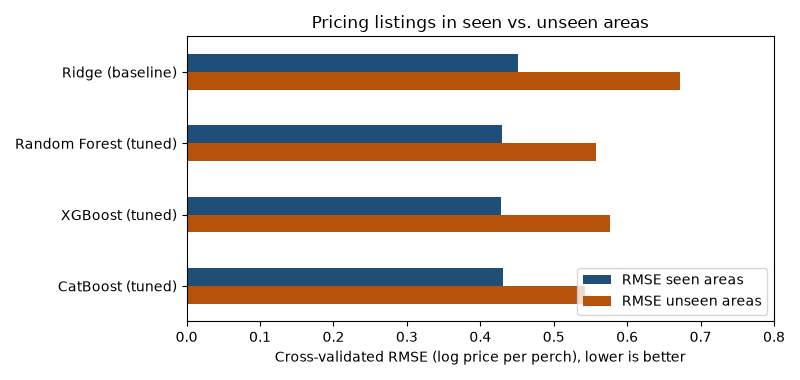

In [5]:
ax = gen[["RMSE seen areas", "RMSE unseen areas"]].plot.barh(figsize=(8, 3.8), color=["#1F4E79", "#B45309"])
ax.set_xlabel("Cross-validated RMSE (log price per perch), lower is better")
ax.set_title("Pricing listings in seen vs. unseen areas")
ax.invert_yaxis()
ax.set_xlim(0, 0.8)
ax.legend(loc="lower right")
plt.tight_layout()

## 3. What this means

*The interpretation is written up in the report (section 6.3), using the numbers above.*

Practical consequences for the project:

- The app only offers areas from the dataset, so the **seen-area** numbers from notebook 02 are the right
  measure of how the app will perform.
- The location fields in the app are **shown for information only**, not editable. Editing them would create
  location values that never occurred in the data.
- A better dataset would geocode each **plot** rather than each area. Then the distance features would carry
  real information within an area as well.